# 56 · REINFORCE: 정책의 확률을 직접 미분하기

📎 **이번 질문** · 선택한 행동의 보상만 받았는데, 어떻게 행동 확률 전체를 더 좋은 방향으로 움직일까요?

Q에서 최대 행동을 고르는 대신 행동 확률 자체를 파라미터로 만듭니다. 가능한 경로가 네 개인 작은 환경에서 정확한 기대 보상·정확 미분·샘플 추정을 각각 구하고, 새 경로를 수집하며 실제 정책을 학습합니다. NumPy·CPU만 사용하며 다른 노트북의 실행 상태를 빌리지 않습니다.

- 준비물: 02 softmax, 12 기댓값, [27 샘플 기울기](../04_생성/27_monte_carlo_gradients.ipynb), [52 Bellman](52_mdp_bellman.ipynb), [53 return](53_mc_td.ipynb)입니다.
- 순서: 경로 확률 → 정확 미분 → return과 baseline → 실제 REINFORCE → 독립 정책 평가입니다.
- 반드시 가져갈 세 가지: **경로 분포를 미분한다 / 할인 축과 평균 분모를 적는다 / 고정 표본의 대리 손실과 실제 보상을 구분한다**입니다.

| 표시 | 읽을 내용 |
|---|---|
| 🔑 | 기호·shape·계산 |
| 🔍 | 그림 해석과 검산 |
| 📎 | 용어·코드·출처 |
| ✏️ | 핵심 한두 줄 연습 |

[학습 경로](../../docs/CURRICULUM.md) · [그림 보조 코드](../../src/utils/reinforce_plots.py)

In [1]:
# 준비 셀: 모델·확률 계산은 본문에, 배치·색·글씨는 보조 파일에 둡니다.
import sys
from pathlib import Path
import numpy as np
project_root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'src/utils/plotting.py').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0,str(project_root))
from src.utils import setup_plots,run_check
from src.utils.gradcheck import numerical_gradient
from src.utils.reinforce_plots import (plot_pg_panels,plot_pg_variance,
    plot_pg_learning,plot_pg_evaluation)
setup_plots()

'Arial Unicode MS'

## 🔑 1. 행동 확률을 곱해 경로의 확률을 만듭니다

**이 절에서 가져갈 것:** 정책과 환경을 분리하고, 시작 상태의 기대 보상을 경로 합으로 씁니다.

배달을 시작하며 안전한 길 또는 위험한 길을 고릅니다. 두 번째 행동 뒤 반드시 종료합니다. 54번의 환경에서 **첫 보상만 안전+.2, 위험−.1로 바꿔** 과거 보상을 제거하는 계산도 볼 수 있게 합니다.

| 상태 | 행동0 | 행동1 |
|---|---|---|
| 시작0 | 안전2로 이동, +.2 | 위험1로 이동, −.1 |
| 위험1 | 종료3, +2 | 종료3, −14 |
| 안전2 | 종료3, +.7 | 종료3, +.7 |
| 종료3 | 보상0·추가 행동 없음 | 보상0·추가 행동 없음 |

> **용어** · **확률 정책 πθ(a\|s)**는 상태별 행동의 확률입니다. **logits θ**는 softmax 전 점수입니다. **경로 τ**는 상태·행동·보상의 한 실행 기록입니다. **return G₀**은 그 경로에서 받은 할인 보상 합입니다.

비종료 상태만 학습하므로 θ와 π의 shape는 `(3,2)`입니다. $\pi(a|s)=e^{\theta_{sa}}/\sum_j e^{\theta_{sj}}$, $\gamma=.9$로 둡니다. 초기 상태와 환경 전이는 결정적이고 θ와 무관합니다.

$$P_\theta(\tau)=\pi_\theta(a_0|0)\pi_\theta(a_1|s_1),\quad
G_0=r_0+\gamma r_1,\quad J(\theta)=\sum_{\tau=1}^4P_\theta(\tau)G_0(\tau).$$

아래는 균등 정책의 네 경로입니다. 경로 순서는 안전a0·안전a1·위험a0·위험a1입니다. 안전한 길의 두 행동은 결과가 같아도 서로 다른 표본 경로입니다.

In [2]:
uniform_path_probability=np.full((4,1),.25)
path_reward_example=np.array([[.2,.7],[.2,.7],[-.1,2.],[-.1,-14.]])
path_returns=path_reward_example@np.array([1.,.9])
path_contribution=uniform_path_probability[:,0]*path_returns

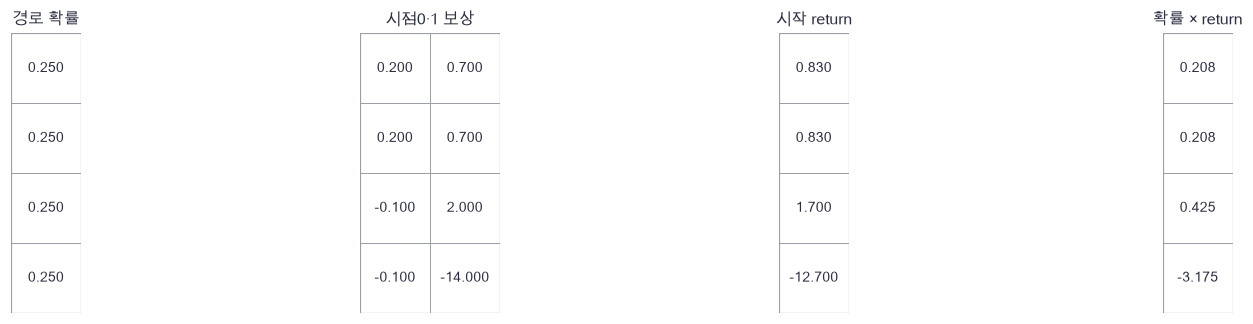

In [3]:
plot_pg_panels([uniform_path_probability,path_reward_example,path_returns[:,None],path_contribution[:,None]],['경로 확률','시점0·1 보상','시작 return','확률 × return'])

🔍 **확인** · 네 기여의 합이 정확한 시작 가치 −2.335입니다. 안전 경로를 항상 고르면 .83, 위험 경로에서 좋은 행동만 고르면1.7입니다. 지금 정책은 실수 행동도 선택하므로 최적값과 다릅니다.

> **코드** · `np.column_stack`은 열을 붙이고, `array[:,None]`은 열 축을 더합니다. `max(axis=1,keepdims=True)`는 행동 축 최대를 `(S,1)`로 남깁니다. softmax에서 행 최대를 빼면 확률은 같고 exp overflow를 피할 수 있습니다.

In [4]:
def pg_environment():
    """시작 보상만54번에서 바꾼4상태·2행동 환경. 모든 경로는2전이 뒤 종료합니다."""
    next_state=np.array([[2,1],[3,3],[3,3],[3,3]])
    rewards=np.array([[.2,-.1],[2.,-14.],[.7,.7],[0.,0.]])
    return next_state,rewards

In [5]:
def softmax_policy(theta):
    """비종료3상태 logits:(3,2)에서 행동 축 softmax와 안정적 log확률을 구합니다."""
    shifted=theta-theta.max(axis=1,keepdims=True)
    logprob=shifted-np.log(np.exp(shifted).sum(axis=1,keepdims=True))
    return np.exp(logprob),logprob

In [6]:
def enumerate_pg(theta,gamma=.9):
    """가능한4경로의 확률,상태·행동·보상:(4,2),시작 return:(4,)를 열거합니다."""
    # 쓰는 것: softmax_policy, pg_environment (앞 정의 셀)
    policy,_=softmax_policy(theta)
    next_state,rewards=pg_environment()
    paths=[]
    for first in range(2):
        second_state=next_state[0,first]
        for second in range(2):
            probability=policy[0,first]*policy[second_state,second]
            paths.append((probability,second_state,first,second))
    paths=np.array(paths)
    states=np.column_stack([np.zeros(4,dtype=int),paths[:,1].astype(int)])
    actions=paths[:,2:4].astype(int)
    reward= rewards[states,actions]
    returns=reward[:,0]+gamma*reward[:,1]
    return paths[:,0],states,actions,reward,returns

In [7]:
uniform_theta=np.zeros((3,2))
probability,states,actions,rewards,returns=enumerate_pg(uniform_theta)
np.testing.assert_allclose(probability.sum(),1.)  # 검산: 가능한 모든 경로의 질량 합
np.testing.assert_allclose(returns,[.83,.83,1.7,-12.7])  # 검산: 손계산 두 시점 보상
np.testing.assert_allclose(probability@returns,-2.335)  # 검산: 균등 정책의 정확 J
np.testing.assert_allclose(softmax_policy(uniform_theta+1000)[0],.5)  # 검산: 공통 상수 불변
assert states.shape==actions.shape==rewards.shape==(4,2), '경로 축과 시간 축을 공유합니다'

### ✏️ 연습 1 · 한 경로의 확률

연습은 코딩 테스트처럼 **함수 뼈대가 미리 있고 핵심 한두 줄만 비어 있습니다.** `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓴 뒤, 셀을 실행하고 바로 아래 검사 셀을 실행하세요. 아직 채우지 않았으면 안내문만 나오고, 값이 다르면 "손계산과 다릅니다"가 나옵니다. 막히면 그 아래 "정답 보기"를 펼칩니다.

두 시점에 실제 선택한 행동의 조건부 확률을 곱하세요.

In [8]:
def exercise_path_probability(selected_probabilities):
    """한 경로의 확률의 핵심 계산입니다."""
    ### 구현할 내용: 두 시점에 실제 선택한 행동의 조건부 확률을 곱하세요.
    raise NotImplementedError
    return probability

In [9]:
def check_path_probability(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([.4,.8])),.32)  # 검산: 독립 환경 전이1의 경로 확률
    print("연습 1 통과")

run_check(check_path_probability,exercise_path_probability,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_path_probability: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
probability = np.prod(selected_probabilities)
```

</details>

## 🔑 2. log-derivative로 정확한 정책 기울기를 구성합니다

**이 절에서 가져갈 것:** 보상 함수를 미분하지 않고, 그 보상을 받는 경로의 확률을 미분합니다.

위험한 길의 나쁜 행동 확률을 조금 줄이면 기대 보상이 얼마나 달라질까요? 이산 행동 번호를 미분하는 대신 $\nabla P=P\nabla\log P$를 씁니다. 여기서는 네 경로의 유한합이므로 미분과 합의 교환에 근사도 필요 없습니다.

$$\nabla J=\sum_\tau P(\tau)G_0(\tau)\sum_{t=0}^1\nabla\log\pi(a_t|s_t).$$
$$\frac{\partial\log\pi(a|s)}{\partial\theta_{sj}}=\mathbf1[j=a]-\pi(j|s).$$

> **용어** · **score-function**은 로그확률의 파라미터 기울기입니다. **REINFORCE**는 이 기댓값을 실제 수집 경로의 평균으로 추정해 정책을 갱신하는 방법입니다. 이 score는32번의 입력에 대한 density score와 미분 대상이 다릅니다.

독립 검산을 위해 경로 score와 별도로 조건부 기댓값을 직접 미분합니다. $v_1=2\pi_{10}-14\pi_{11}$, $q_0=[.2+.9(.7),-.1+.9v_1]$이면 $J=\pi_0^Tq_0$입니다.

$$\nabla_{\theta_0}J=\pi_0\odot(q_0-J),\qquad
\nabla_{\theta_1}J=.9\pi_{01}\pi_1\odot([2,-14]-v_1),\qquad
\nabla_{\theta_2}J=0.$$

아래 손계산은 균등 정책입니다. 상태1의 미분에 도달 확률.5와 할인.9가 모두 들어갑니다.

In [10]:
hand_branches=np.array([.83,-5.5])
hand_value=np.array([[-2.335]])
hand_gradient=np.array([[1.5825,-1.5825],[1.8,-1.8],[0.,0.]])

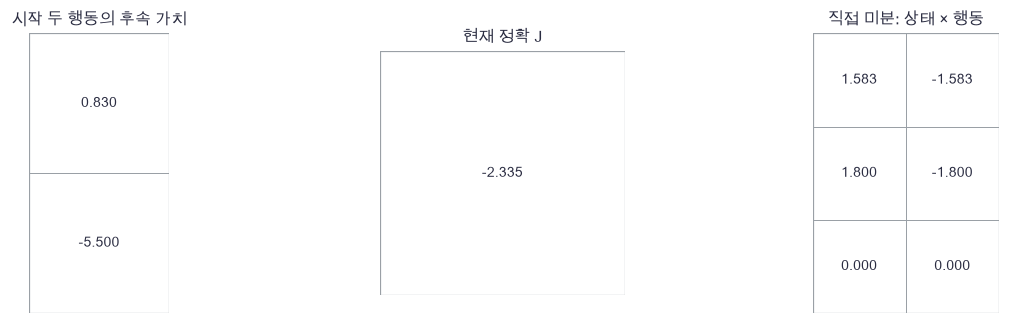

In [11]:
plot_pg_panels([hand_branches[:,None],hand_value,hand_gradient],['시작 두 행동의 후속 가치','현재 정확 J','직접 미분: 상태 × 행동'])

🔍 **확인** · 지금은 위험 상태에서 실수 확률이 커서 시작의 안전 행동을 늘리는 미분이 나옵니다. 동시에 위험 상태 안에서는 좋은 행동을 늘립니다. 안전 상태의 두 행동은 보상이 같아 정확한 미분이0입니다. 최적 행동과 현재 정책에서의 개선 방향을 구분합니다.

> **코드** · `np.eye(A)[actions]`는 행동 번호를 one-hot으로 바꿉니다. `np.add.at`은 같은 상태가 여러 번 등장해도 미분을 모두 더합니다. `numerical_gradient`는 각 원소를 ±h로 바꾸고 원래 값을 복원하는 중심차분입니다.

In [12]:
def exact_pg(theta,gamma=.9):
    """경로 score를 쓰지 않고 두 단계 조건부기댓값을 직접 미분한 J와 전체gradient입니다."""
    # 쓰는 것: softmax_policy (앞 절)
    policy,_=softmax_policy(theta)
    risky=policy[1]@np.array([2.,-14.])
    branch=np.array([.2+gamma*.7,-.1+gamma*risky])
    value=policy[0]@branch
    gradient=np.zeros_like(theta)
    gradient[0]=policy[0]*(branch-value)
    gradient[1]=gamma*policy[0,1]*policy[1]*(np.array([2.,-14.])-risky)
    state_values=np.array([value,risky,.7])
    return float(value),gradient,state_values

In [13]:
def trajectory_gradients(theta,states,actions,weights):
    """고정 weights:(B,T)에 log-policy 미분을 곱한 경로별 gradient:(B,S,A)입니다."""
    # 쓰는 것: softmax_policy (앞 절)
    policy,_=softmax_policy(theta)
    scores=np.eye(policy.shape[1])[actions]-policy[states]
    gradients=np.zeros((len(states),*theta.shape))
    for episode in range(len(states)):
        np.add.at(gradients[episode],states[episode],weights[episode,:,None]*scores[episode])
    return gradients

In [14]:
def enumerated_objective():
    """경로를 모두 더한 독립 목적값입니다."""
    # 쓰는 것: enumerate_pg (1절), check_theta (다음 실행 셀)
    probability,_,_,_,returns=enumerate_pg(check_theta)
    return probability@returns

In [15]:
# 쓰는 것: enumerate_pg, hand_gradient, uniform_theta (앞 절의 계산·정의 셀)
j0,gradient0,values0=exact_pg(uniform_theta)
np.testing.assert_allclose(gradient0,hand_gradient)  # 검산: 조건부 기댓값의 손미분
check_theta=np.array([[.2,-.1],[-.4,.3],[.1,.5]])
check_p,check_s,check_a,check_r,check_g=enumerate_pg(check_theta)
exact_j,exact_gradient,exact_values=exact_pg(check_theta)
full_weights=np.repeat(check_g[:,None],2,axis=1)
full_gradients=trajectory_gradients(check_theta,check_s,check_a,full_weights)
score_expectation=np.sum(check_p[:,None,None]*full_gradients,axis=0)
numeric=numerical_gradient(enumerated_objective,check_theta)
np.testing.assert_allclose(score_expectation,exact_gradient,atol=1e-12)  # 검산: 두 독립 미분 경로
np.testing.assert_allclose(numeric,exact_gradient,atol=1e-8)  # 검산: 전체6파라미터 중심차분
np.testing.assert_allclose(exact_gradient.sum(axis=1),0.,atol=1e-12)  # 검산: 상태별 공통 logits 이동 불변
print('전체 gradient 중심차분 최대 절대오차:',np.max(np.abs(numeric-exact_gradient)))

전체 gradient 중심차분 최대 절대오차: 1.0049605592143962e-10


### ✏️ 연습 2 · softmax의 로그확률 미분

선택 행동의 one-hot에서 정책 확률을 빼세요.

In [16]:
def exercise_score(probabilities,action):
    """softmax의 로그확률 미분의 핵심 계산입니다."""
    ### 구현할 내용: 선택 행동의 one-hot에서 정책 확률을 빼세요.
    raise NotImplementedError
    return score

In [17]:
def check_score(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([.3,.7]),1),[-.3,.3])  # 검산: 합이0인 score
    print("연습 2 통과")

run_check(check_score,exercise_score,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_score: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
score = np.eye(len(probabilities))[action] - probabilities
```

</details>

## 🔑 3. 과거 보상과 상태 baseline을 빼도 기대 미분은 같습니다

**이 절에서 가져갈 것:** 무엇을 빼도 되는지 조건을 적고, 분산과 편향을 따로 계산합니다.

두 번째 행동은 이미 받은 첫 보상을 바꿀 수 없습니다. 현재 시점 기준 $G_t=\sum_{k=t}^{1}\gamma^{k-t}r_k$를 사용하면

$$\nabla J=E\left[\sum_t\gamma^t G_t\nabla\log\pi(a_t|s_t)\right].$$

$G_t$ 안의 할인은 현재 시점부터이고 **밖의 γᵗ는 시작 시점으로 맞춥니다.** 둘째 항은 γr₁입니다. 과거 r₀에 곱해진 둘째 score는 상태를 조건으로 평균하면0이므로 제거할 수 있습니다.

> **용어** · **reward-to-go**는 현재 이후의 보상만 모은 return입니다. **baseline b(s)**는 행동을 뽑기 전에 고정된 상태별 기준입니다. **불편 추정**은 반복 수집의 기댓값이 정확 미분과 같다는 뜻이며 한 배치의 정확성을 뜻하지 않습니다.

$$\sum_a\pi(a|s)\nabla\log\pi(a|s)=\nabla\sum_a\pi(a|s)=0,$$
$$\nabla J=E\left[\sum_t\gamma^t(G_t-b(s_t))\nabla\log\pi(a_t|s_t)\right].$$

이번에는 정확한 Vπ를 baseline으로 넣어 항등식을 검사합니다. 실제 학습 절에서는 Vπ 정답을 제공하지 않고 이전 배치에서 회귀한 baseline을 씁니다. 행동이나 현재 관측 return에 의존하는 값을 아무렇게나 빼면 위 증명이 성립하지 않습니다.

In [18]:
hand_reward_to_go=np.column_stack([check_g,check_r[:,1]])
hand_discounted=hand_reward_to_go*np.array([1.,.9])
hand_baseline_weight=(hand_reward_to_go-exact_values[check_s])*[1.,.9]

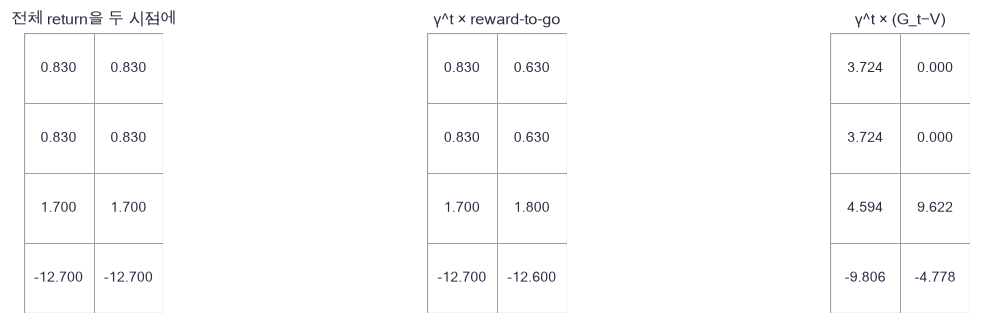

In [19]:
plot_pg_panels([full_weights,hand_discounted,hand_baseline_weight],['전체 return을 두 시점에','γ^t × reward-to-go','γ^t × (G_t−V)'])

🔍 **확인** · 같은 경로의 개별 gradient는 바뀔 수 있습니다. 불변인 것은 네 경로에 원래 확률을 곱해 모두 더한 기대 gradient입니다. 모든 시점의 가중치를 똑같이 놓는 전체-return 식과 γᵗ를 곱하는 reward-to-go 식을 섞지 않습니다.

In [20]:
def reward_to_go(rewards,gamma=.9):
    """에피소드별 보상:(B,T)에서 현재 시점 기준 할인 return G_t를 역순 계산합니다."""
    result=np.zeros_like(rewards)
    running=np.zeros(len(rewards))
    for time in range(rewards.shape[1]-1,-1,-1):
        running=rewards[:,time]+gamma*running
        result[:,time]=running
    return result

In [21]:
# 쓰는 것: check_a, check_p, check_r, check_s, check_theta, exact_gradient, full_gradients, trajectory_gradients (앞 절의 계산·정의 셀)
computed_returns=reward_to_go(check_r)
np.testing.assert_allclose(computed_returns,hand_reward_to_go)  # 검산: 역순 재귀와 두 시점 손계산
rtg_gradients=trajectory_gradients(check_theta,check_s,check_a,hand_discounted)
baseline_gradients=trajectory_gradients(check_theta,check_s,check_a,hand_baseline_weight)
bad_gradients=trajectory_gradients(check_theta,check_s,check_a,(computed_returns-computed_returns)*[1.,.9])
gradient_groups=np.stack([full_gradients,rtg_gradients,baseline_gradients,bad_gradients])
expected_gradients=np.sum(check_p[None,:,None,None]*gradient_groups,axis=1)
variance_trace=np.sum(check_p[None,:,None,None]*(gradient_groups-expected_gradients[:,None])**2,axis=(1,2,3))
gradient_bias=np.linalg.norm((expected_gradients-exact_gradient).reshape(4,-1),axis=1)
np.testing.assert_allclose(expected_gradients[:3],np.broadcast_to(exact_gradient,(3,3,2)),atol=1e-12)  # 검산: 허용한 세 추정의 기대
assert gradient_bias[3]>0, '관측return자체를 빼면0이 되어 진짜gradient를 잃습니다'

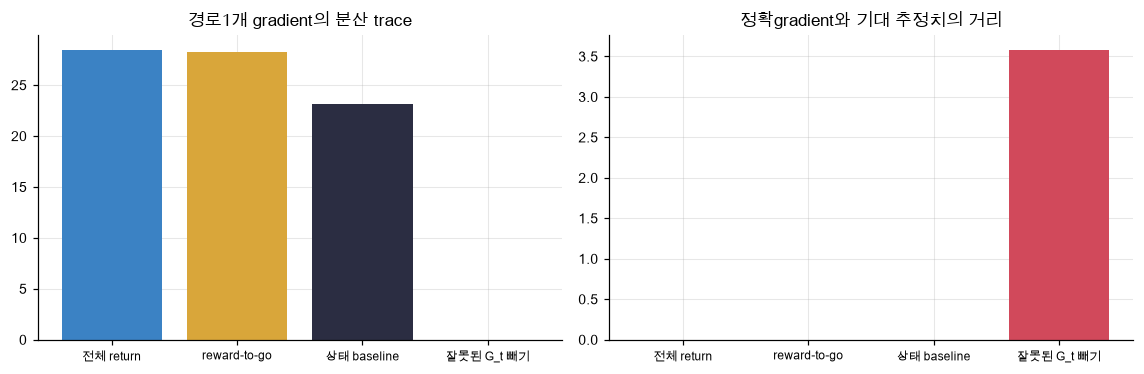

In [22]:
plot_pg_variance(['전체 return','reward-to-go','상태 baseline','잘못된 G_t 빼기'],variance_trace,gradient_bias)

🔍 **확인** · 이 고정 정책에서는 세 올바른 추정의 분산 trace가 약28.49·28.29·23.15입니다. 잘못된 추정의 분산은0이지만 편향이 있습니다. 모든 baseline이 분산을 줄이거나 Vπ가 항상 최적이라는 주장은 하지 않습니다. 독립 경로 B개의 평균이면 이 분산 trace는 B로 나뉩니다.

> **코드** · `np.stack`은 새 방법 축을 만듭니다. 여기서는 `(방법,경로,상태,행동)`입니다. `sum(axis=(1,2,3))`은 경로·상태·행동을 합해 방법별 분산 trace를 남깁니다.

### ✏️ 연습 3 · 시작 시점에 맞춘 advantage 가중치

γ^t와 현재 시점 return에서 baseline을 뺀 값을 곱하세요.

In [23]:
def exercise_discounted_weight(returns,baseline,gamma):
    """시작 시점에 맞춘 advantage 가중치의 핵심 계산입니다."""
    ### 구현할 내용: γ^t와 현재 시점 return에서 baseline을 뺀 값을 곱하세요.
    raise NotImplementedError
    return weights

In [24]:
def check_discounted_weight(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([3.,2.]),np.array([1.,.5]),.9),[2.,1.35])  # 검산: 둘째 시점에만 .9
    print("연습 3 통과")

run_check(check_discounted_weight,exercise_discounted_weight,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_discounted_weight: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
weights = gamma**np.arange(len(returns)) * (returns-baseline)
```

</details>

## 🔑 4. 새 경로를 모아 REINFORCE를 실제 학습합니다

**이 절에서 가져갈 것:** 매번 현재 정책에서 수집하고, 고정한 weight로 한 번 갱신합니다.

세 seed5601·5602·5603마다 baseline 없음/학습한 baseline을 비교합니다. θ=0, baseline=0에서 시작하고 **250회×16개 경로×2전이=8,000전이**를 사용합니다. θ의 SGD 학습률은.08, baseline 회귀 학습률은.1로 미리 정합니다.

고정 배치의 대리 손실과 baseline 목적은
$$L_\pi=-\frac1B\sum_{n=1}^B\sum_t w_{nt}\log\pi_\theta(a_{nt}|s_{nt}),\quad w_{nt}=\gamma^t(G_{nt}-b_{old}(s_{nt})),$$
$$L_b=\frac1{2B}\sum_{n,t}(b(s_{nt})-G_{nt})^2.$$

**분모 B는 경로 수**입니다. 시간 축까지 평균하면 두 시점이므로 gradient 규모가 절반이 됩니다. policy는 `θ -= .08 ∇Lπ`로, baseline은 별도 배열에서 갱신합니다. 둘 다 같은 배치의 고정 타깃을 사용하며 actor weight를 만든 뒤 baseline을 적합합니다.

> **용어** · **대리 손실**은 고정된 표본에서 원하는 미분을 만드는 계산식입니다. 그 숫자가 실제 정책 보상 자체는 아닙니다. **on-policy 수집**은 갱신할 현재 정책으로 새 경로를 뽑는 것입니다. **MC baseline**은 완료 경로 return에 회귀한 상태 가치로, 다음 V로 bootstrap하지 않습니다.

정확한 J는 그림의 기록에만 사용하고 gradient·baseline·행동 선택에 넣지 않습니다. 같은 seed의 방법도 정책이 달라지면 경로가 달라집니다. 동일 예산 비교이며 동일 데이터 학습은 아닙니다.

In [25]:
pg_plan=np.array([[3,250,16,2,8000],[3,250,16,2,8000]])

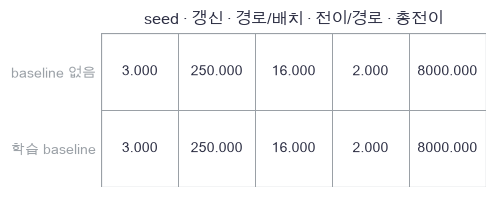

In [26]:
plot_pg_panels([pg_plan],['seed · 갱신 · 경로/배치 · 전이/경로 · 총전이'],[['baseline 없음','학습 baseline']])

🔍 **확인** · 두 방법은 환경 상호작용 예산이 같지만 baseline 회귀 연산은 추가됩니다. 값 추정의 효과를 보기 위한 작은 실험이며 총 계산시간까지 같은 비교는 아닙니다. 정확한4경로 합으로 학습하는 방법도 가능하지만 여기의 정책 갱신은 실제 표본만 사용합니다.

> **코드** · `rng.random((B,2))`는 두 행동을 선택할 균등수입니다. 확률 p₀와 비교해 두 행동 중 하나를 고릅니다. `.copy()`는 baseline 값을 갱신 배열과 분리합니다. `states.ravel()`은 경로·시간 축을 한 줄로 펴 상태별 회귀 기여를 누적합니다.

In [27]:
def sample_pg(theta,count,rng):
    """현재 정책으로 실제2전이 경로를 수집합니다. 외부 가치표를 행동 선택에 쓰지 않습니다."""
    # 쓰는 것: softmax_policy, pg_environment (앞 절)
    policy,_=softmax_policy(theta)
    next_state,rewards=pg_environment()
    uniforms=rng.random((count,2))
    first=(uniforms[:,0]>=policy[0,0]).astype(int)
    second_state=next_state[0,first]
    second=(uniforms[:,1]>=policy[second_state,0]).astype(int)
    states=np.column_stack([np.zeros(count,dtype=int),second_state])
    actions=np.column_stack([first,second])
    return states,actions,rewards[states,actions]

In [28]:
def fixed_pg_loss(theta,states,actions,weights):
    """표본·weight를 고정한 −평균(sum_t weight*logπ)와 전체 미분입니다."""
    # 쓰는 것: softmax_policy, trajectory_gradients (앞 절)
    _,logprob=softmax_policy(theta)
    loss=-np.mean(np.sum(weights*logprob[states,actions],axis=1))
    gradient=-trajectory_gradients(theta,states,actions,weights).mean(axis=0)
    return float(loss),gradient

In [29]:
# 쓰는 것: check_theta (앞 절의 계산·정의 셀)
def frozen_batch_objective():
    """이미 수집한 배치와 weight를 고정한 대리 목적입니다."""
    # 쓰는 것: fixed_pg_loss와 다음 실행 셀의 check_theta, sample_states, sample_actions, sample_weights
    return fixed_pg_loss(check_theta,sample_states,sample_actions,sample_weights)[0]

In [30]:
# 쓰는 것: check_theta, reward_to_go, trajectory_gradients (앞 절의 계산·정의 셀)
sample_states,sample_actions,sample_rewards=sample_pg(check_theta,16,np.random.default_rng(5690))
sample_weights=reward_to_go(sample_rewards)*[1.,.9]
fixed_loss,fixed_gradient=fixed_pg_loss(check_theta,sample_states,sample_actions,sample_weights)
fixed_numeric=numerical_gradient(frozen_batch_objective,check_theta)
np.testing.assert_allclose(fixed_gradient,fixed_numeric,atol=1e-8)  # 검산: 표본과weight를 고정한 전체 미분
np.testing.assert_allclose(-fixed_gradient,trajectory_gradients(check_theta,sample_states,sample_actions,sample_weights).mean(axis=0))  # 검산: 손실 최소화=보상 기울기 상승
assert np.all(np.isin(sample_actions,[0,1])), '매 전이에서 실제 행동 하나를 뽑습니다'

In [31]:
def train_reinforce(seed,use_baseline,steps=250,batch_size=16,learning_rate=.08):
    """매 갱신에 새 경로를 수집하고 policy1회·MC baseline1회를 따로 갱신합니다."""
    # 쓰는 것: exact_pg, sample_pg, reward_to_go, fixed_pg_loss (앞 절·정의 셀)
    # 1. baseline은 이전 배치까지 학습한 표로 시작하며 모든 파라미터는0에서 출발합니다.
    theta=np.zeros((3,2))
    baseline=np.zeros(3)
    rng=np.random.default_rng(seed)
    history=[]
    observed=[]
    for step in range(steps+1):
        if step%25==0:
            history.append([step,exact_pg(theta)[0],*baseline])
        if step==steps:
            break
        # 2. 현재 정책·이전 baseline으로 가중치를 먼저 고정하고 actor를 한 번 갱신합니다.
        states,actions,rewards=sample_pg(theta,batch_size,rng)
        returns=reward_to_go(rewards)
        frozen_baseline=baseline[states].copy() if use_baseline else np.zeros_like(returns)
        weights=(.9**np.arange(2))*(returns-frozen_baseline)
        loss,gradient=fixed_pg_loss(theta,states,actions,weights)
        theta-=learning_rate*gradient
        observed.append(returns[:,0].mean())
        # 3. 같은 수집 경로의 return으로 baseline만 회귀합니다. actor와 계산 그래프를 공유하지 않습니다.
        if use_baseline:
            residual=baseline[states]-returns
            value_gradient=np.zeros_like(baseline)
            np.add.at(value_gradient,states.ravel(),residual.ravel()/batch_size)
            baseline-=.1*value_gradient
    return theta,baseline,np.array(history),np.array(observed)

In [32]:
training_seeds=[5601,5602,5603]
method_names=['baseline 없음','학습 baseline']
pg_models=[]
pg_histories=[]
pg_observations=[]
for use_baseline in [False,True]:
    group_models,group_history,group_observed=[],[],[]
    for seed in training_seeds:
        theta,baseline,history,observed=train_reinforce(seed,use_baseline)
        group_models.append(theta)
        group_history.append(history)
        group_observed.append(observed)
    pg_models.append(group_models)
    pg_histories.append(group_history)
    pg_observations.append(group_observed)
pg_models=np.array(pg_models)
pg_histories=np.array(pg_histories)
pg_observations=np.array(pg_observations)
assert pg_models.shape==(2,3,3,2), '방법·seed·상태·행동을 따로 유지합니다'
assert np.all(np.isfinite(pg_models)), '모든 실제 갱신 결과가 유한해야 합니다'
print('총 실제 수집 전이:',2*3*250*16*2)

총 실제 수집 전이: 48000


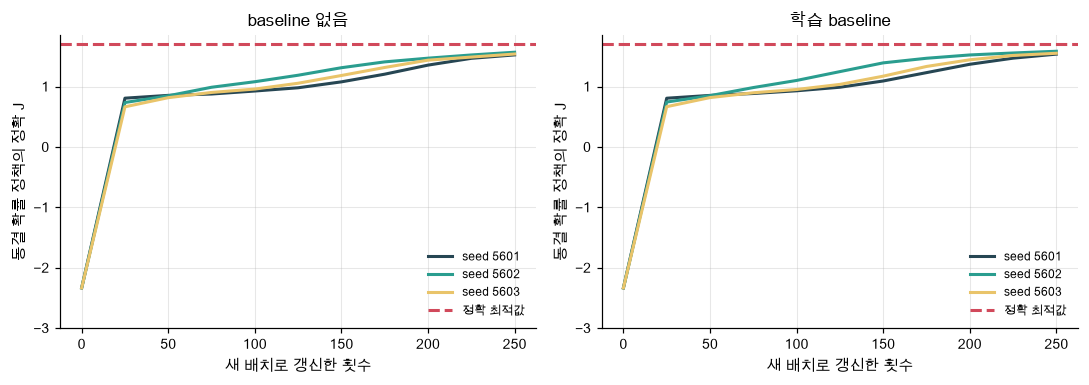

In [33]:
plot_pg_learning(pg_histories,method_names,1.7)

🔍 **확인** · 모든 seed를 표시했습니다. 초기에는 위험 실수 때문에 안전 경로를 늘리다가 위험 상태의 좋은 행동도 학습하며 J가 올라갑니다. 고정 예산의 최종 J는 약1.52–1.58이고 정확한 최적값1.7에 도달하지 않았습니다. 이 세 seed 결과만으로 baseline의 보편적인 성능 우위를 주장하지 않습니다.

### ✏️ 연습 4 · 보상 기울기로 파라미터 갱신

gradient가 ∇J일 때 상승 방향으로 한 스텝 움직이세요.

In [34]:
def exercise_ascent(theta,gradient,learning_rate):
    """보상 기울기로 파라미터 갱신의 핵심 계산입니다."""
    ### 구현할 내용: gradient가 ∇J일 때 상승 방향으로 한 스텝 움직이세요.
    raise NotImplementedError
    return updated

In [35]:
def check_ascent(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,2.]),np.array([.5,-1.]),.2),[1.1,1.8])  # 검산: J기울기 상승 부호
    print("연습 4 통과")

run_check(check_ascent,exercise_ascent,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_ascent: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
updated = theta + learning_rate*gradient
```

</details>

## 🔑 5. 정책을 고정하고 새 경로의 보상을 평가합니다

**이 절에서 가져갈 것:** 학습 손실·훈련 중 보상·최종 정책 가치는 서로 다른 숫자입니다.

학습이 끝난 여섯 정책을 고정합니다. 학습 seed+100의 새 난수로 각각2,048경로를 수집하고 시작 return 평균과 표준오차를 계산합니다. 설정을 고르거나 재학습하지 않습니다. 같은 네 경로를 열거한 정확 J도 함께 비교합니다.

$$\widehat J=\frac1M\sum_nG_{0,n},\qquad SE=\frac{\operatorname{std}(G_0;ddof=1)}{\sqrt M}.$$

이 SE는 **고정된 정책**의 독립 경로 평균에 대한 것입니다. 세 학습 seed의 변동이나 새 환경 일반화 불확실성은 포함하지 않습니다. 평가에서도 π로 표본을 뽑으며 argmax로 바꾸지 않습니다.

먼저 학습된 시작 상태의 확률을 봅니다. 시작에서 위험 경로를 선택하는 비율이 높아도, 그 안의 실수 확률이 남으면 가치가 깎일 수 있습니다.

In [36]:
# 쓰는 것: method_names, pg_models, softmax_policy, training_seeds (앞 절의 계산·정의 셀)
final_policy_rows=np.array([softmax_policy(theta)[0][0] for group in pg_models for theta in group])
final_labels=[f'{name} {seed}' for name in method_names for seed in training_seeds]

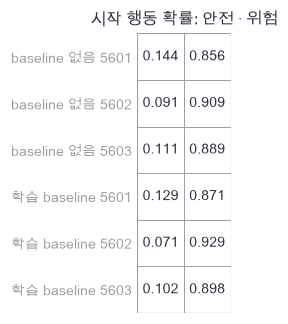

In [37]:
plot_pg_panels([final_policy_rows],['시작 행동 확률: 안전 · 위험'],[final_labels])

🔍 **확인** · 평가할 객체는 학습된 확률 정책입니다. argmax 배포로 바꾸면 정의가 다른 정책이므로 별도 평가해야 합니다. 안전 상태의 두 행동은 같은 보상을 주어 서로 다르게 확률을 배워도 이 환경의 J는 바뀌지 않습니다.

In [38]:
def evaluate_reinforce(theta,seed,count=2048):
    """동결 확률 정책의 새 경로 평균·SE를 exact J와 대조합니다. argmax정책으로 바꾸지 않습니다."""
    # 쓰는 것: sample_pg, reward_to_go, exact_pg (앞 절)
    _,_,rewards=sample_pg(theta,count,np.random.default_rng(seed))
    returns=reward_to_go(rewards)[:,0]
    return returns.mean(),returns.std(ddof=1)/np.sqrt(count),exact_pg(theta)[0]

In [39]:
# 쓰는 것: pg_models, pg_observations, training_seeds (앞 절의 계산·정의 셀)
evaluation=[]
for group in pg_models:
    for seed,theta in zip(training_seeds,group):
        before=theta.copy()
        evaluation.append(evaluate_reinforce(theta,seed+100))
        np.testing.assert_array_equal(theta,before)  # 검산: 평가 중 정책 갱신 없음
evaluation=np.array(evaluation)
assert evaluation.shape==(6,3), '정책6개마다 평균·SE·정확J를 기록합니다'
assert np.all(evaluation[:,1]>=0), '평가 표준오차는 음수가 아닙니다'
for label,row in zip(final_labels,evaluation):
    print(label,dict(zip(['mean','SE','exact_J'],np.round(row,5))))
print('전체 학습 중 실제 return 평균:',np.mean(pg_observations,axis=2))

baseline 없음 5601 {'mean': np.float64(1.52438), 'SE': np.float64(0.02077), 'exact_J': np.float64(1.52306)}
baseline 없음 5602 {'mean': np.float64(1.58753), 'SE': np.float64(0.01655), 'exact_J': np.float64(1.56741)}
baseline 없음 5603 {'mean': np.float64(1.54902), 'SE': np.float64(0.02061), 'exact_J': np.float64(1.53783)}
학습 baseline 5601 {'mean': np.float64(1.5467), 'SE': np.float64(0.01947), 'exact_J': np.float64(1.53597)}
학습 baseline 5602 {'mean': np.float64(1.60622), 'SE': np.float64(0.01637), 'exact_J': np.float64(1.58372)}
학습 baseline 5603 {'mean': np.float64(1.562), 'SE': np.float64(0.01936), 'exact_J': np.float64(1.55023)}
전체 학습 중 실제 return 평균: [[0.995435  1.13618   1.068755 ]
 [1.0082675 1.171415  1.0631975]]


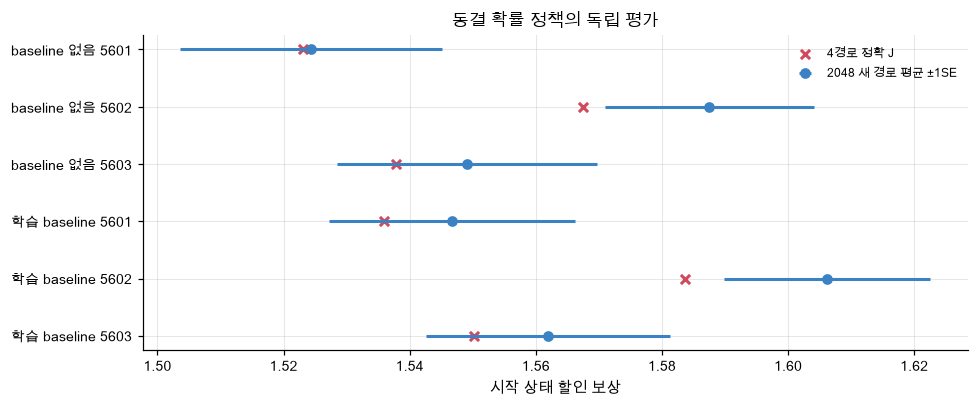

In [40]:
plot_pg_evaluation(final_labels,evaluation[:,2],evaluation[:,0],evaluation[:,1])

🔍 **확인** · 점과 막대는 평가 경로의 평균±1SE이고 빨간 표시는 근사가 없는 네 경로 합입니다. 1SE는 반드시 정답을 포함하는 구간이 아닙니다. 큰 음의 보상이 드물어지면 유한 표본 평균과 SE도 흔들릴 수 있으므로 이 예제에서는 정확 J를 함께 남깁니다. 실험은 이 환경·예산·세 학습 seed의 관측입니다.

고정 배치의 대리 손실을 계속 줄이는 것으로 새 정책의 보상이 보장되지는 않습니다. 다음 단원의 actor–critic은 완료 return 대신 학습한 가치와 TD를 연결하고, PPO는 old policy를 고정한 확률비로 수집 배치 재사용을 다룹니다.

### ✏️ 연습 5 · 평균의 표준오차

독립 경로 return의 표본표준편차를 sqrt(M)으로 나누세요.

In [41]:
def exercise_standard_error(returns):
    """평균의 표준오차의 핵심 계산입니다."""
    ### 구현할 내용: 독립 경로 return의 표본표준편차를 sqrt(M)으로 나누세요.
    raise NotImplementedError
    return standard_error

In [42]:
def check_standard_error(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([1.,3.])),1.)  # 검산: 표본표준편차sqrt2, 경로수2
    print("연습 5 통과")

run_check(check_standard_error,exercise_standard_error,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_standard_error: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
standard_error = returns.std(ddof=1)/np.sqrt(len(returns))
```

</details>

## ✏️ 끝 연습 A–D

경로 합·score 평균·할인 재귀·고정 baseline을 작은 숫자로 다시 확인합니다.

### ✏️ 연습 A · 정확한 기대 보상

경로 확률과 return을 곱해 모두 더하세요.

In [43]:
def exercise_exact_return(probabilities,returns):
    """정확한 기대 보상의 핵심 계산입니다."""
    ### 구현할 내용: 경로 확률과 return을 곱해 모두 더하세요.
    raise NotImplementedError
    return value

In [44]:
def check_exact_return(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([.25,.75]),np.array([2.,-2.])),-1.)  # 검산: 확률 가중합
    print("연습 A 통과")

run_check(check_exact_return,exercise_exact_return,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_exact_return: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
value = np.sum(probabilities*returns)
```

</details>

### ✏️ 연습 B · score의 기대값은0

행동 확률로 score의 행동 축을 평균하세요.

In [45]:
def exercise_mean_score(probabilities,scores):
    """score의 기대값은0의 핵심 계산입니다."""
    ### 구현할 내용: 행동 확률로 score의 행동 축을 평균하세요.
    raise NotImplementedError
    return expected

In [46]:
def check_mean_score(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([.3,.7]),np.array([[.7,-.7],[-.3,.3]])),[0.,0.],atol=1e-14)  # 검산: baseline 제거의 근거
    print("연습 B 통과")

run_check(check_mean_score,exercise_mean_score,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_mean_score: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
expected = (probabilities[:,None]*scores).sum(axis=0)
```

</details>

### ✏️ 연습 C · 두 시점 reward-to-go

첫 시점에는 할인한 미래를 더하고 마지막에는 현재 보상만 남기세요.

In [47]:
def exercise_two_returns(rewards,gamma):
    """두 시점 reward-to-go의 핵심 계산입니다."""
    ### 구현할 내용: 첫 시점에는 할인한 미래를 더하고 마지막에는 현재 보상만 남기세요.
    raise NotImplementedError
    return returns

In [48]:
def check_two_returns(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(np.array([.2,.7]),.9),[.83,.7])  # 검산: 현재시점 기준 할인
    print("연습 C 통과")

run_check(check_two_returns,exercise_two_returns,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_two_returns: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
returns = np.array([rewards[0]+gamma*rewards[1],rewards[1]])
```

</details>

### ✏️ 연습 D · 고정 상태 baseline의 미분

한 상태에서 1/2 mean((b−G)^2)의 기울기를 계산하세요.

In [49]:
def exercise_baseline_gradient(prediction,returns):
    """고정 상태 baseline의 미분의 핵심 계산입니다."""
    ### 구현할 내용: 한 상태에서 1/2 mean((b−G)^2)의 기울기를 계산하세요.
    raise NotImplementedError
    return gradient

In [50]:
def check_baseline_gradient(candidate):
    """작은 손계산 입력과 경계 조건을 검사합니다."""
    np.testing.assert_allclose(candidate(2.,np.array([1.,5.])),-1.)  # 검산: target을 미분하지 않는 평균잔차
    print("연습 D 통과")

run_check(check_baseline_gradient,exercise_baseline_gradient,hint="본문 수식의 축과 부호를 확인하세요.")

☐ exercise_baseline_gradient: 아직 채우지 않았습니다. `raise NotImplementedError` 줄을 지우고 그 자리에 코드를 쓰세요.
   힌트: 본문 수식의 축과 부호를 확인하세요.


📎 **정답** · 막히면 펼쳐 보고, 다시 접고 스스로 써 보세요.

<details>
<summary>정답 보기</summary>

```python
gradient = np.mean(prediction-returns)
```

</details>

## ✏️ 준비도 확인

- **설명:** 이산 행동 번호 대신 경로 확률을 미분하는 이유를 말할 수 있나요?
- **수식:** 시작 return의 목적에 맞춰 reward-to-go 바깥의 γᵗ와 경로 평균 분모를 쓸 수 있나요?
- **구현:** score를 반복 상태에 누적하고, actor 갱신 동안 baseline·관측 return을 고정할 수 있나요?
- **변형 검산:** 보상·정책·할인율을 바꾸어 직접 미분·경로 전수열거·중심차분을 비교할 수 있나요?

## 📎 참고와 다음 연결

[Spinning Up의 정책 기울기 유도](https://spinningup.openai.com/en/latest/spinningup/rl_intro3.html)는 log-derivative, 과거 보상 제거와 상태 baseline의 근거를 설명합니다. 이 노트북은 별도의 두 전이 할인 목적을 정하고 γᵗ를 명시해 유한합으로 다시 검산했습니다. [27 샘플 기울기](../04_생성/27_monte_carlo_gradients.ipynb)의 score-function이 경로 분포에 적용된 셈입니다. 57에서는 TD critic·advantage·GAE, 58에서는 old policy·PPO로 연결합니다.